In [1]:
import os
from astropy.io import fits
from pathlib import Path

def print_fits_info(identifier):
    paths = Path('./data').glob(f'*{identifier}*')
    for path in paths:
        hdul = fits.open(path)
        print(hdul.info())

print('Mosaic fits files:')
print_fits_info('MOSAIC')
print('\nPhotometric Detections')
print_fits_info('MER_FINAL')
print('\nPhotometric redshift estimations and classifications')
print_fits_info('PHZ')
print('\nSpectroscopic Measurements')
print_fits_info('SPE')

# Output path
out_dir = './outputs/first_plots'
os.makedirs(out_dir, exist_ok=True)

Mosaic fits files:
Filename: data/EUC_MER_BGSUB-MOSAIC-VIS_TILE102159484-116033_20241025T015934.885975Z_00.00.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      48   (19200, 19200)   float32   
None
Filename: data/EUC_MER_BGSUB-MOSAIC-NIR-J_TILE102159484-C026DB_20241024T213141.416722Z_00.00.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      48   (19200, 19200)   float32   
None
Filename: data/EUC_MER_BGSUB-MOSAIC-NIR-Y_TILE102159484-A9CCA7_20241024T221227.957725Z_00.00.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      48   (19200, 19200)   float32   
None
Filename: data/EUC_MER_BGSUB-MOSAIC-NIR-H_TILE102159484-39CF67_20241024T214009.099906Z_00.00.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      48   (19200, 19200)   float32   
None

Photometric Detections
Filename: data/EUC_

                                                                                 [astropy.io.fits.card]


None
Filename: data/EUC_SPE_WIDE-CAT-Z-102159484_N_20241110T054253.801351Z_00.00.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      12   ()      
  1  SPE_QUALITY    1 BinTableHDU     59   111422R x 25C   [K, I, I, K, K, K, K, K, K, K, K, K, K, 8A, E, E, I, I, I, I, I, I, I, I, I]   
  2  SPE_CLASSIFICATION    1 BinTableHDU     19   15713R x 5C   [K, E, E, E, 8A]   
  3  SPE_GALAXY_CANDIDATES    1 BinTableHDU     33   77044R x 12C   [K, I, E, E, E, E, 48A, E, E, E, E, 80E]   
  4  SPE_STAR_CANDIDATES    1 BinTableHDU     25   28816R x 8C   [K, I, E, E, E, E, 48A, E]   
  5  SPE_QSO_CANDIDATES    1 BinTableHDU     33   73736R x 12C   [K, I, E, E, E, E, 48A, E, E, E, E, 80E]   
None


In [2]:
data = fits.getdata('./data/EUC_MER_FINAL-CAT_TILE102159484-EF6D85_20241026T003047.133877Z_00.00.fits')
data.columns

ColDefs(
    name = 'OBJECT_ID'; format = 'K'; unit = 'NA'; null = 9223372036854775807
    name = 'RIGHT_ASCENSION'; format = 'D'; unit = 'deg'
    name = 'DECLINATION'; format = 'D'; unit = 'deg'
    name = 'RIGHT_ASCENSION_PSF_FITTING'; format = 'D'; unit = 'deg'
    name = 'DECLINATION_PSF_FITTING'; format = 'D'; unit = 'deg'
    name = 'SEGMENTATION_MAP_ID'; format = 'K'; unit = 'NA'; null = 9223372036854775807
    name = 'VIS_DET'; format = 'I'; unit = 'NA'; null = 32767
    name = 'FLUX_VIS_1FWHM_APER'; format = 'E'; unit = 'uJy'
    name = 'FLUX_VIS_2FWHM_APER'; format = 'E'; unit = 'uJy'
    name = 'FLUX_VIS_3FWHM_APER'; format = 'E'; unit = 'uJy'
    name = 'FLUX_VIS_4FWHM_APER'; format = 'E'; unit = 'uJy'
    name = 'FLUX_Y_1FWHM_APER'; format = 'E'; unit = 'uJy'
    name = 'FLUX_Y_2FWHM_APER'; format = 'E'; unit = 'uJy'
    name = 'FLUX_Y_3FWHM_APER'; format = 'E'; unit = 'uJy'
    name = 'FLUX_Y_4FWHM_APER'; format = 'E'; unit = 'uJy'
    name = 'FLUX_J_1FWHM_APER'; format 

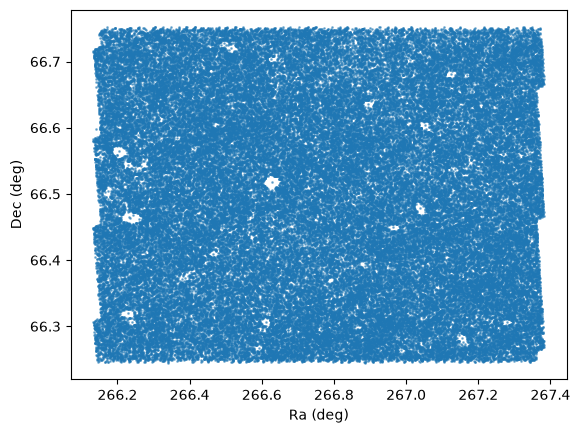

In [3]:
import matplotlib.pyplot as plt

plt.scatter(data['RIGHT_ASCENSION'], data['DECLINATION'], s=1, alpha=0.5)
plt.xlabel('Ra (deg)')
plt.ylabel('Dec (deg)')
plt.savefig(os.path.join(out_dir, 'sky_chart.png'), bbox_inches='tight')
plt.show()

In [13]:
from bokeh.plotting import figure, show
from bokeh.io import output_notebook

output_notebook()

fig = figure(
    title='Bokeh Sky Chart',
    x_axis_label='Ra (deg)',
    y_axis_label='Dec (deg)',
)

fig.scatter(data['RIGHT_ASCENSION'], data['DECLINATION'], size=1, alpha=0.5)
show(fig)

Loading BokehJS ...

In [25]:
morphology = fits.getdata('data/EUC_MER_FINAL-MORPH-CAT_TILE102159484-AE979F_20241026T003045.182961Z_00.00.fits')
morphology.columns

ColDefs(
    name = 'OBJECT_ID'; format = 'K'; unit = 'NA'; null = 9223372036854775807
    name = 'CONCENTRATION'; format = 'E'; unit = 'NA'
    name = 'CONCENTRATION_ERR'; format = 'E'; unit = 'NA'
    name = 'ASYMMETRY'; format = 'E'; unit = 'NA'
    name = 'ASYMMETRY_ERR'; format = 'E'; unit = 'NA'
    name = 'SMOOTHNESS'; format = 'E'; unit = 'NA'
    name = 'SMOOTHNESS_ERR'; format = 'E'; unit = 'NA'
    name = 'GINI'; format = 'E'; unit = 'NA'
    name = 'GINI_ERR'; format = 'E'; unit = 'NA'
    name = 'MOMENT_20'; format = 'E'; unit = 'NA'
    name = 'MOMENT_20_ERR'; format = 'E'; unit = 'NA'
    name = 'SERSIC_VISNIR_REDUCED_CHI2'; format = 'E'; unit = 'NA'
    name = 'SERSIC_VISNIR_ITERATIONS'; format = 'J'; unit = 'NA'; null = 2147483647
    name = 'SERSIC_VISNIR_FLAGS'; format = 'K'; unit = 'NA'; null = 9223372036854775807
    name = 'SERSIC_VISNIR_DURATION'; format = 'E'; unit = 's'
    name = 'SERSIC_SERSIC_VIS_RADIUS'; format = 'E'; unit = 'arcsec'
    name = 'SERSIC_SERS

In [54]:
import numpy as np
arr = morphology['BAR_STRONG']

print("Total entries:", len(arr))
print("Valid entries:", np.sum(~np.isnan(arr)))
print("NaN entries:", np.sum(np.isnan(arr)))

valid = morphology[~np.isnan(arr)]
print(len(valid))
print(valid['BAR_STRONG'].min(), valid['BAR_STRONG'].max())
print(valid['BAR_STRONG'])

Total entries: 111422
Valid entries: 913
NaN entries: 110509
913
0.0 74.096466
[ 3.8456063  2.3694167  5.9986987  1.6314337  2.7036676  6.052477
  2.2810855  1.2798438  4.153491  37.98902    3.376583   3.2806792
  4.26283    1.1960695 10.996453   1.3010988 30.324972   1.6600082
  0.         1.2414137  1.4528105  1.3425658  2.5248804  3.5847733
  4.00377    4.936434   1.9655714  3.1586895  1.6158799  1.4132241
  4.4676404  6.950835   1.1434267  2.0821967  3.6611328  8.454824
  4.8381157 15.211479   2.3831198  6.8615355 12.469608   1.4828006
  1.1682132  3.2304773  9.001619   1.7978767  4.076318   1.2625138
 11.387188  35.209404   1.6633341  9.651832   2.0205598  1.6709278
  1.1708508  2.62642    1.2149761  1.3727525  1.5877346  1.458166
  2.7547429  2.933405   1.2882719  1.2489686  1.1761943  3.395904
  2.62808    1.808984   1.7365346 74.096466   5.823452  72.53328
  2.0015428  2.843968   2.5277534  1.1812756  2.0792673  1.3866434
  0.         1.1901567  2.7369537 28.652195   3.606076  

Instances are assigned a number for each morphological feature. This MIGHT be a percentage (e.e. 0=definitely not, 100=definitely yes).
Most have NaN for 'BAR_STRONG'. This could mean that this was never evaluated for this source. This could be because it is not a galaxy, or that some other classifications meant that this question is not asked for the source.